# Análise de Contato com Atrito utilizando o Método dos Elementos de Contorno (MEC)

Este *notebook* apresenta a implementação de uma formulação bidimensional do Método dos Elementos de Contorno (MEC) aplicada a problemas de contato elastostático com atrito.

O código foi estruturado para suportar malhas não conformes na interface de contato, eliminando a restrição de coincidência nodal entre os domínios. Para isso, utiliza-se o mapeamento *Node-to-Segment* para a transferência de trações e projeção de deslocamentos. O acoplamento impõe as restrições de impenetrabilidade de Signorini e a lei de atrito de Coulomb, sendo o problema de contato resolvido de forma iterativa através do algoritmo de Uzawa.

**Geração e Importação da Malha:**
A geometria e a discretização do domínio são realizadas integrando o gerador **Gmsh** diretamente no ambiente de execução. A biblioteca **meshio** é então utilizada para realizar a leitura, extração da conectividade e mapeamento das regiões físicas e condições de contorno definidas na malha para as estruturas de dados do Python.

---

## Propostas de Trabalhos Futuros

Para pesquisadores e alunos que desejam expandir esta formulação, algumas possibilidades de continuação incluem:

* **Integração com Mecânica da Fratura:** Expandir o código base para avaliar processos de propagação de trincas induzidas por atrito (*fretting fatigue*). Isso possibilitaria o estudo de tolerância ao dano em montagens sujeitas a forças inerciais e de contato severo, como os encaixes de palhetas em rotores de turbinas aeronáuticas.
* **Computação de Alto Desempenho (HPC):** Como as matrizes do MEC são densas e assimétricas, um excelente avanço seria transcrever os laços de integração numérica e montagem do sistema utilizando Cython e OpenMP para contornar o *Global Interpreter Lock* (GIL) do Python. Além disso, a paralelização do solver de contato em múltiplos processos via MPI (utilizando ferramentas como `petsc4py` e `mpi4py`) permitiria escalar a análise para malhas de grande porte.
* **Extensão Tridimensional (3D):** Substituir as soluções fundamentais planas por soluções volumétricas e adaptar a lógica de projeção ortogonal para *Node-to-Surface*, abrindo caminho para análises de contato tridimensionais.


In [2]:
!pip install meshio[all]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.2/166.2 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 64.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 51.0 MB/s eta 0:00:00


In [3]:
!apt-get update
!apt-get install gmsh
!python -m pip install gmsh

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Hit:3 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:4 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]
Get:5 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]
Get:6 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Get:7 https://cli.github.com/packages stable/main amd64 Packages [355 B]
Get:8 http://archive.ubuntu.com/ubuntu jammy-backports InRelease [127 kB]
Get:9 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ Packages [101 kB]
Get:10 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease [18.1 kB]
Hit:11 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Get:12 https://r2u.stat.illinois.edu/ubuntu jammy/main amd64 Packages [3,131 kB]
Get:13 http://archive.ubuntu.com/ubuntu jammy-updates/universe amd64 Packages [1,616 kB]
Get:14 https://

Gerando malha com Gmsh...




Visualizando geometria e problema...


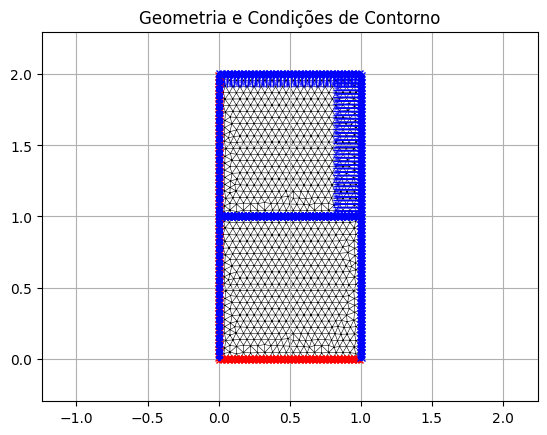

Montando matrizes de influência BEM...
Iniciando solver de contato com atrito...
Contato convergido na iteração 39663. Erro: 4.91e-06
Recuperando resultados globais...
Gerando gráficos...


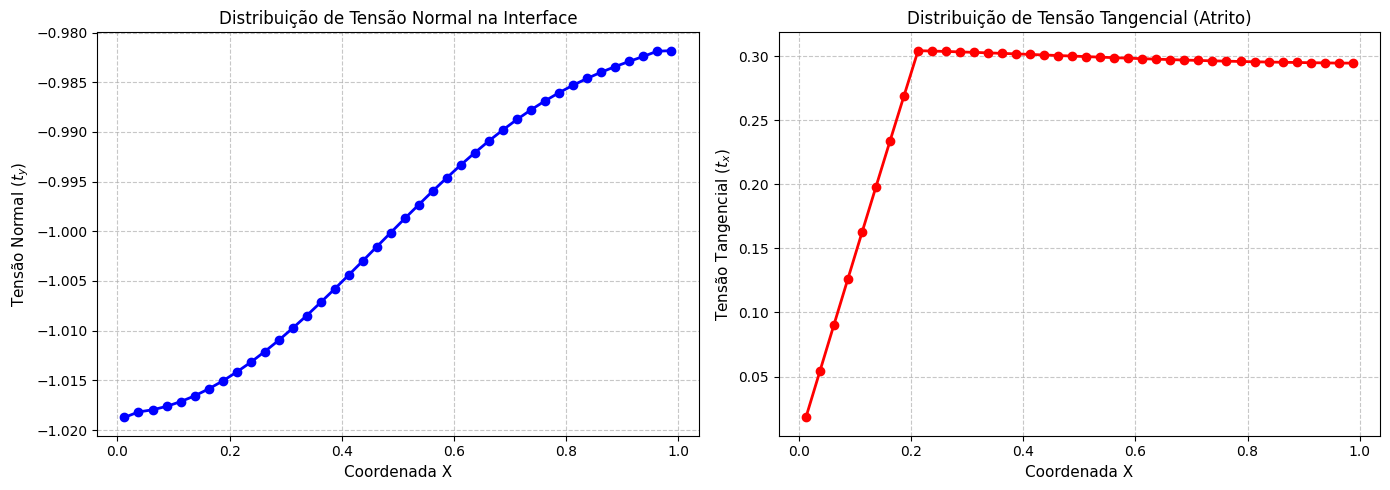

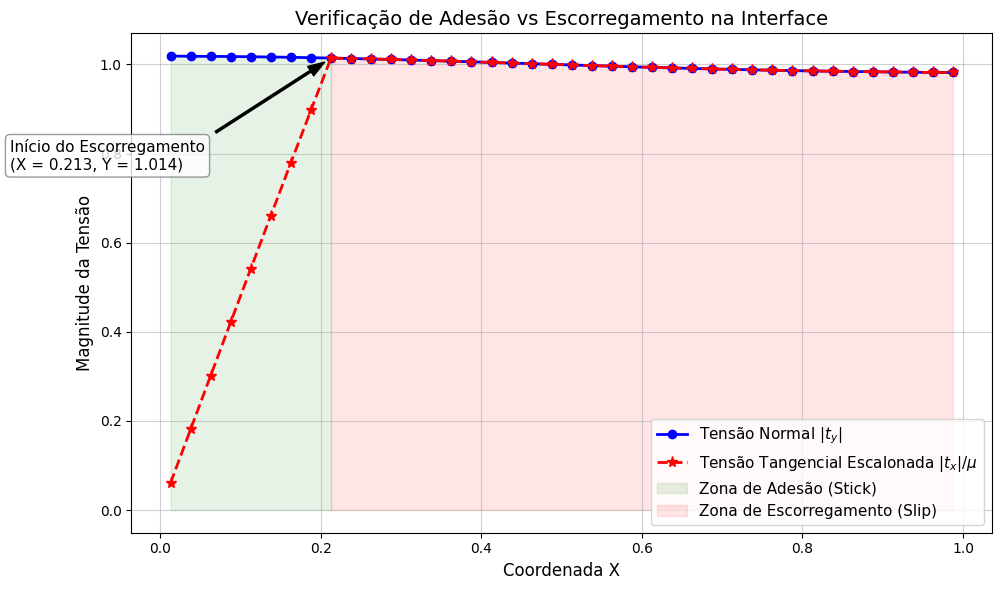

Deslocamento máximo real: 3.6367e-11
Fator de escala aplicado: 5499548127.22


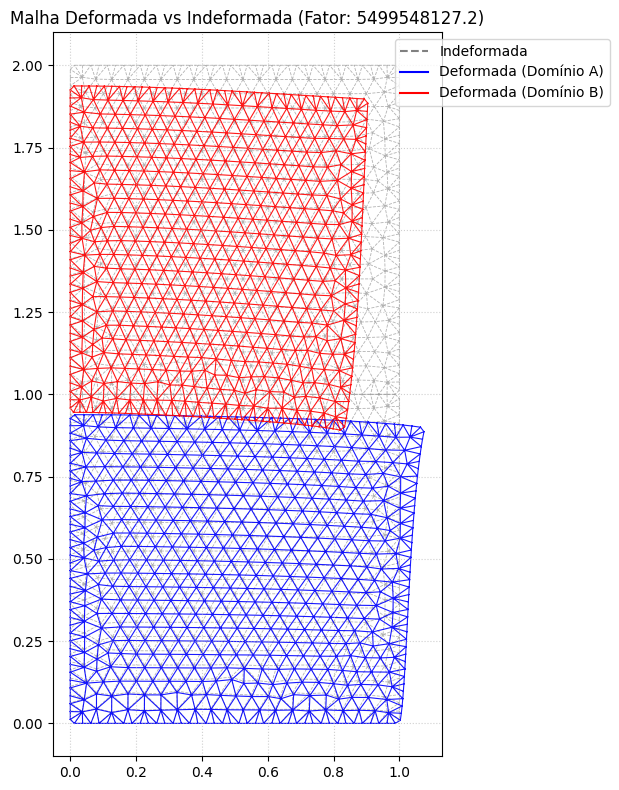

In [4]:
# -*- coding: utf-8 -*-
"""
Código de Elementos de Contorno para análise de contato com atrito.
Permite nós não coincidentes na interface utilizando formulação Node-to-Segment.
"""

import os
import subprocess
import numpy as np
import meshio
import matplotlib.pyplot as plt
import matplotlib.tri as triang
from matplotlib.lines import Line2D
from matplotlib import cm

# =============================================================================
# 1. GERAÇÃO DA MALHA E ENTRADA DE DADOS
# =============================================================================

def generate_geometry_and_mesh(file_name):
    """Gera o arquivo .geo e executa o Gmsh para criar a malha."""
    geo_code = """ref=.05;
Point(1) = {0, 0, 0, ref};
Point(2) = {1, 0, 0, ref};
Point(3) = {1, 1, 0, ref};
Point(4) = {0, 1, 0, ref};
Point(5) = {1, 2, 0, ref};
Point(6) = {0, 2, 0, ref};

Line(1) = {1, 2};
Line(2) = {2, 3};
Line(3) = {3, 4};
Line(4) = {4, 1};
Line Loop(1) = {1, 2, 3, 4};
Plane Surface(1) = {1};
Line(5) = {4, 3};
Line(6) = {3, 5};
Line(7) = {5, 6};
Line(8) = {6, 4};
Line Loop(2) = {5, 6, 7, 8};
Plane Surface(2) = {2};

Physical Curve("disp1") = {1};
Physical Curve("disp2") = {4,8};
Physical Curve("trac1") = {2,4};
Physical Curve("intrf") = {3,5};
Physical Curve("trac2") = {7};
Physical Curve("trac3") = {6};
Physical Surface("surf1") = {1};
Physical Surface("surf2") = {2};
"""
    with open(f"{file_name}.geo", "w") as f:
        f.write(geo_code)

    print("Gerando malha com Gmsh...")
    subprocess.run(['gmsh', '-2', f'{file_name}.geo', '-o', f'{file_name}.msh'],
                   stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

def input_data():
    """Define parâmetros de entrada e condições de contorno."""
    bound_cond = {
        'disp1': {'type_n': 0, 'value_n': 0, 'type_t': 0, 'value_t': 0},
        'disp2': {'type_n': 0, 'value_n': 0, 'type_t': 1, 'value_t': 0},
        'trac2': {'type_n': 1, 'value_n': 0, 'type_t': 1, 'value_t': -1},
        'trac1': {'type_n': 1, 'value_n': 0, 'type_t': 1, 'value_t': 0},
        'trac3': {'type_n': 1, 'value_n': -2., 'type_t': 1, 'value_t': 0},
        'intrf': {'type_n': 1, 'value_n': 0, 'type_t': 1, 'value_t': 0},
    }
    E = 70.0e9
    nu = 0.3
    file_name = 'placa'
    qpoint = {'type': 'rot', 'omega': 0, 'rho' : 0}

    return {'bound_cond': bound_cond, 'E': E, 'nu': nu, 'file_name': file_name, 'qpoint': qpoint}

def compute_inodes(file_name, bound_cond):
    """Lê o arquivo de malha e extrai as informações topológicas e condições de contorno."""
    mesh = meshio.read(file_name + '.msh')
    coordinates = mesh.points
    line_elements = mesh.cells_dict['line']
    triangle_elements = mesh.cells_dict['triangle']
    segments = mesh.cell_data_dict['gmsh:physical']['line']

    bc_info = {}
    for key, value in bound_cond.items():
        segment = mesh.field_data[key][0]
        bc_info[key] = {
            'type_n': value['type_n'],
            'value_n': value['value_n'],
            'segment': segment,
            'type_t': value['type_t'],
            'value_t': value['value_t']
        }

    boundary_nodes = np.unique(line_elements)
    all_nodes = np.unique(triangle_elements)
    internal_nodes = [node for node in all_nodes if node not in boundary_nodes]

    return {
        'boundary_nodes': boundary_nodes,
        'internal_nodes': internal_nodes,
        'all_nodes': all_nodes,
        'coordinates': coordinates,
        'line_elements': line_elements,
        'triangle_elements': triangle_elements,
        'segments': segments,
        'bc_info': bc_info,
        'mesh': mesh
    }

def mount_bcs(segments, bc_info):
    """Constrói a matriz de condições de contorno (bcs) para cada elemento."""
    num_elements = len(segments)
    bcs = np.zeros((2*num_elements, 4), dtype=np.float64)

    for i, segment_index in enumerate(segments):
        for bc_name, bc_data in bc_info.items():
            if bc_data['segment'] == segment_index:
                tp_n = bc_data['type_n']
                vl_n = bc_data['value_n']
                tp_t = bc_data['type_t']
                vl_t = bc_data['value_t']
                bcs[2*i:2*i+2, 0] = np.array([tp_n, tp_n])
                bcs[2*i:2*i+2, 1] = np.array([vl_n, vl_n])
                bcs[2*i:2*i+2, 2] = np.array([tp_t, tp_t])
                bcs[2*i:2*i+2, 3] = np.array([vl_t, vl_t])
                break
    return bcs

def comp_node_and_normal(elem, nodes):
    """Calcula os nós (pontos de colocação) e vetores normais para os elementos de contorno."""
    num_elements = elem.shape[0]
    node_des = np.zeros((2*num_elements, 2))
    normal = np.zeros((2*num_elements, 2))

    for i in range(num_elements):
        node1, node2 = elem[i]
        x1, y1 = nodes[node1][0:2]
        x2, y2 = nodes[node2][0:2]

        node_des[2*i, :] = [x1 + (x2 - x1) / 4, y1 + (y2 - y1) / 4]
        node_des[2*i+1, :] = [x1 + 3*(x2 - x1) / 4, y1 + 3*(y2 - y1) / 4]

        L = np.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)
        tangent_x = (x2 - x1) / L
        tangent_y = (y2 - y1) / L

        normal[2*i, :] = [tangent_y, -tangent_x]
        normal[2*i+1, :] = [tangent_y, -tangent_x]

    return node_des, normal

def extract_surface_data(mesh):
    """Coleta as sub-regiões (superfícies) e seus respectivos elementos e nós a partir da malha."""
    surface_data = {}
    for key, value in mesh.field_data.items():
        if key.startswith("surf"):
            surface_data[key] = value[0]

    triangles = mesh.cell_data_dict['gmsh:physical']['triangle']
    triangles_surf = {surface: [] for surface in surface_data}

    for i, triangle in enumerate(triangles):
        for surface, element in surface_data.items():
            if triangle == element:
                triangles_surf[surface].append(i)
                break

    tri_elem = mesh.cells_dict['triangle']
    ind_elem = 0
    lines_surf = {surface: [] for surface in surface_data}
    nodes_surf = {surface: [] for surface in surface_data}

    for elem in mesh.cells_dict['line']:
        for surface, tri_list in triangles_surf.items():
            found = False
            for triangle in tri_list:
                if (elem[0] == tri_elem[triangle,0] and elem[1] == tri_elem[triangle,1]) or \
                   (elem[0] == tri_elem[triangle,1] and elem[1] == tri_elem[triangle,2]) or \
                   (elem[0] == tri_elem[triangle,2] and elem[1] == tri_elem[triangle,0]):

                    lines_surf[surface].append(ind_elem)
                    nodes_surf[surface].extend([2*ind_elem, 2*ind_elem+1])
                    found = True
                    break
            if found:
                break
        ind_elem += 1

    return triangles_surf, nodes_surf, lines_surf


# =============================================================================
# 2. INTEGRAÇÃO E MONTAGEM DO MEC
# =============================================================================

def compute_fund_solutions(r1, r2, r, nx, ny, E, nu):
    """Calcula as soluções fundamentais (deslocamentos e trações) da elasticidade plana."""
    mu = E / (2 * (1 + nu))
    rd1 = r1 / r
    rd2 = r2 / r

    c1 = 4 * np.pi * (1 - nu)
    c2 = (3 - 4 * nu) * np.log(1 / r)
    c3 = rd1 * nx + rd2 * ny

    u11 = (c2 + rd1 ** 2) / (2 * c1 * mu)
    u22 = (c2 + rd2 ** 2) / (2 * c1 * mu)
    u12 = (rd1 * rd2) / (2 * c1 * mu)
    u21 = u12

    t11 = -(c3 * ((1 - 2 * nu) + 2 * rd1 ** 2)) / (c1 * r)
    t22 = -(c3 * ((1 - 2 * nu) + 2 * rd2 ** 2)) / (c1 * r)
    t12 = -((c3 * 2 * rd1 * rd2) - (1 - 2 * nu) * (rd1 * ny - rd2 * nx)) / (c1 * r)
    t21 = -((c3 * 2 * rd1 * rd2) - (1 - 2 * nu) * (rd2 * nx - rd1 * ny)) / (c1 * r)

    uast = np.array([[u11, u12], [u21, u22]])
    tast = np.array([[t11, t12], [t21, t22]])
    return uast, tast

def compute_gh_sing(E, nu, x1, x2, y1, y2, n1, n2, xidd):
    """Calcula as matrizes g e h elementares para integração singular."""
    xid = -0.5
    mu = E / (2 * (1 + nu))
    c1 = 4 * np.pi * (1 - nu)
    L = 2 * np.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

    h11 = 0.5
    h22 = 0.5
    h13 = 0.0
    h24 = 0.0

    fin_part = (-2 + np.log(np.abs((1 - xid) / (1 + xid))))
    coef = 2 * (1 - 2 * nu) * ((x2 - x1) * n2 - (y2 - y1) * n1) / (L * c1)
    h12 = coef * fin_part
    h21 = -h12
    h14 = coef * 2
    h23 = -h14

    g11s = -1.781167572309405 + np.log(L / 2)
    g11ns = 4 * (x2 - x1) ** 2 / L ** 2
    g13s = 0.042791644191678246 + np.log(L / 2)
    g13ns = g11ns
    g13 = g13s + g13ns
    g22s = g11s
    g22ns = 4 * (y2 - y1) ** 2 / L ** 2
    g24s = g13s
    g24ns = g22ns

    g11 = -L * (3 - 4 * nu) / (4 * c1 * mu) * g11s + L / (4 * c1 * mu) * g11ns
    g22 = -L * (3 - 4 * nu) / (4 * c1 * mu) * g22s + L / (4 * c1 * mu) * g22ns
    g24 = -L * (3 - 4 * nu) / (4 * c1 * mu) * g24s + L / (4 * c1 * mu) * g24ns
    g13 = -L * (3 - 4 * nu) / (4 * c1 * mu) * g13s + L / (4 * c1 * mu) * g13ns
    g14 = (x2 - x1) * (y2 - y1) / (c1 * L * mu)
    g23 = g14
    g12 = g14
    g21 = g14

    if xidd == -.5:
        g_el = np.array([[g11, g12, g13, g14], [g21, g22, g23, g24]])
        h_el = np.array([[h11, h12, h13, h14], [h21, h22, h23, h24]])
    else:
        g_el = np.array([[g13, g14, g11, g12], [g23, g24, g21, g22]])
        h_el = np.array([[h13, -h14, h11, -h12], [-h23, h24, -h21, h22]])

    return g_el, h_el

def mount_matrices(nodes, normal, E, nu, qpoint_str):
    """Monta as matrizes globais H e G, e o vetor q do MEC."""
    npgauss = 6
    xi, weight = np.polynomial.legendre.leggauss(npgauss)

    nn = nodes.shape[0]
    H = np.zeros((2*nn, 2*nn))
    G = np.zeros((2*nn, 2*nn))
    q = np.zeros(2*nn)

    one_over_2pi = 1 / (2 * np.pi)
    I1 = 1.781167572309405
    I2 = -0.042791644191678246

    for ii in range(nn):
        x0, y0 = nodes[ii]

        for jj in range(nn//2):
            x1, y1 = nodes[2*jj,:]
            x2, y2 = nodes[2*jj+1,:]
            L = 2*np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
            nx, ny = normal[2*jj]

            if ii == 2*jj:
                g_el, h_el = compute_gh_sing(E, nu, x1, x2, y1, y2, nx, ny, -.5)
                G[2*ii:2*ii+2, 4*jj:4*jj+4] = g_el
                H[2*ii:2*ii+2, 4*jj:4*jj+4] = h_el
            elif ii == 2*jj+1:
                g_el, h_el = compute_gh_sing(E, nu, x1, x2, y1, y2, nx, ny, .5)
                G[2*ii:2*ii+2, 4*jj:4*jj+4] = g_el
                H[2*ii:2*ii+2, 4*jj:4*jj+4] = h_el
            else:
                intG = np.zeros((2,4))
                intH = np.zeros((2,4))
                intq = np.zeros(2)
                for kk in range(npgauss):
                    N1 = 0.5 - xi[kk]
                    N2 = 0.5 + xi[kk]
                    N = np.array([[N1, 0, N2, 0], [0, N1, 0, N2]])
                    x = N1 * x1 + N2 * x2
                    y = N1 * y1 + N2 * y2

                    r1 = x - x0
                    r2 = y - y0
                    r = np.sqrt(r1**2 + r2**2)

                    uast, tast = compute_fund_solutions(r1, r2, r, nx, ny, E, nu)

                    if qpoint_str['type'] == 'rot':
                        omega = qpoint_str['omega']
                        rho_dens = qpoint_str['rho']
                        intF = np.zeros(2)
                        theta = np.arctan2(r2, r1)
                        for kkk in range(npgauss):
                            rho = r * (xi[kkk] + 1) / 2
                            rho1 = rho * np.cos(theta)
                            rho2 = rho * np.sin(theta)
                            xint = x0 + rho1
                            yint = y0 + rho2
                            uast2, tast2 = compute_fund_solutions(rho1, rho2, rho, nx, ny, E, nu)
                            f = rho_dens * omega**2 * np.array([xint, yint])
                            intF += uast2.dot(f) * rho * r / 2 * weight[kkk]
                        intq += intF * (nx * r1 + ny * r2) / r**2 * L / 2 * weight[kk]

                    intG += uast.dot(N) * L / 2 * weight[kk]
                    intH += tast.dot(N) * L / 2 * weight[kk]

                H[2*ii:2*ii+2, 4*jj:4*jj+4] = intH
                G[2*ii:2*ii+2, 4*jj:4*jj+4] = intG
                q[2*ii:2*ii+2] += intq
    return H, G, q


# =============================================================================
# 3. SUBESTRUTURAÇÃO E CONDENSAÇÃO
# =============================================================================

def particionar_matrizes(H, G, bcs_externas, idx_interface, nnodes):
    """Separa DOFs em externos (e) e de interface (c), aplicando BCs nos externos."""
    dofs_c = []
    for i in idx_interface:
        dofs_c.extend([2*i, 2*i+1])

    dofs_e = [d for d in range(2*nnodes) if d not in dofs_c]

    H_ee = H[np.ix_(dofs_e, dofs_e)]
    H_ec = H[np.ix_(dofs_e, dofs_c)]
    H_ce = H[np.ix_(dofs_c, dofs_e)]
    H_cc = H[np.ix_(dofs_c, dofs_c)]

    G_ee = G[np.ix_(dofs_e, dofs_e)]
    G_ec = G[np.ix_(dofs_e, dofs_c)]
    G_ce = G[np.ix_(dofs_c, dofs_e)]
    G_cc = G[np.ix_(dofs_c, dofs_c)]

    n_e = len(dofs_e)
    A_ee = np.zeros((n_e, n_e))
    A_ce = np.zeros((len(dofs_c), n_e))
    f_e  = np.zeros(n_e)
    f_c  = np.zeros(len(dofs_c))

    for idx_local, idx_global in enumerate(dofs_e):
        no_id = idx_global // 2
        gdl   = idx_global % 2

        tipo_bc = bcs_externas[no_id, gdl * 2]
        valor_bc = bcs_externas[no_id, gdl * 2 + 1]

        if tipo_bc == 0:
            A_ee[:, idx_local] = -G_ee[:, idx_local]
            A_ce[:, idx_local] = -G_ce[:, idx_local]
            f_e -= H_ee[:, idx_local] * valor_bc
            f_c -= H_ce[:, idx_local] * valor_bc
        else:
            A_ee[:, idx_local] = H_ee[:, idx_local]
            A_ce[:, idx_local] = H_ce[:, idx_local]
            f_e += G_ee[:, idx_local] * valor_bc
            f_c += G_ce[:, idx_local] * valor_bc

    return A_ee, A_ce, H_ec, H_cc, G_ec, G_cc, f_e, f_c, dofs_e, dofs_c

def condensacao_estatica(A_ee, A_ce, H_ec, H_cc, G_ec, G_cc, f_e, f_c):
    """Calcula a Matriz de Flexibilidade F e o vetor livre q da interface via Complemento de Schur."""
    invA_H = np.linalg.solve(A_ee, H_ec)
    invA_G = np.linalg.solve(A_ee, G_ec)
    invA_f = np.linalg.solve(A_ee, f_e)

    S_H = H_cc - A_ce @ invA_H
    S_G = G_cc - A_ce @ invA_G
    f_hat = f_c - A_ce @ invA_f

    F = np.linalg.solve(S_H, S_G)
    q = np.linalg.solve(S_H, f_hat)

    return F, q, invA_H, invA_G, invA_f


# =============================================================================
# 4. FORMULAÇÃO DO CONTATO (NODE-TO-SEGMENT) E ATRITO
# =============================================================================

def construir_operadores_projecao(coords_A, coords_B):
    """Constrói as matrizes de projeção ortogonal (M) e transferência de tração (Mt) para malhas não conformes."""
    n_nos_A = len(coords_A)
    n_nos_B = len(coords_B)

    M = np.zeros((2 * n_nos_A, 2 * n_nos_B))
    W_A = np.zeros(2 * n_nos_A)
    W_B = np.zeros(2 * n_nos_B)

    for i in range(0, n_nos_A, 2):
        dist = np.linalg.norm(coords_A[i+1] - coords_A[i])
        W_A[2*i : 2*i+2] = dist
        W_A[2*i+2 : 2*i+4] = dist

    for j in range(0, n_nos_B, 2):
        dist = np.linalg.norm(coords_B[j+1] - coords_B[j])
        W_B[2*j : 2*j+2] = dist
        W_B[2*j+2 : 2*j+4] = dist

    for i in range(n_nos_A):
        ponto_A = coords_A[i]
        min_dist = np.inf
        best_j = -1
        best_t = 0

        for j in range(0, n_nos_B, 2):
            v1 = coords_B[j]
            v2 = coords_B[j+1]

            vec_v = v2 - v1
            vec_w = ponto_A - v1

            t = np.dot(vec_w, vec_v) / (np.dot(vec_v, vec_v) + 1e-14)
            proj = v1 + t * vec_v
            dist = np.linalg.norm(ponto_A - proj)

            if dist < min_dist and -0.51 <= t <= 1.51:
                min_dist = dist
                best_j = j
                best_t = t

        if best_j != -1:
            N1 = 1.0 - best_t
            N2 = best_t
            M[2*i, 2*best_j]       = N1
            M[2*i, 2*best_j + 2]   = N2
            M[2*i+1, 2*best_j + 1] = N1
            M[2*i+1, 2*best_j + 3] = N2

    Mt = np.diag(1.0 / W_B) @ M.T @ np.diag(W_A)
    return M, Mt

def resolver_contato_nao_conforme(F_A, q_A, F_B, q_B, normais_A, M, Mt, mu=0.3, max_iter=10000, tol=1e-6, relaxamento=0.01):
    """Algoritmo iterativo tipo Uzawa para contato com atrito (Condições de Signorini e Coulomb)."""
    F_eq = F_A + M @ F_B @ Mt
    q_eq = q_A - M @ q_B

    n_dofs = len(q_eq)
    n_nos = n_dofs // 2
    t_c_A = np.zeros(n_dofs)
    t_c_A_old = np.copy(t_c_A)

    eps = (1.0 / np.mean(np.diag(F_eq))) * relaxamento

    for iteracao in range(max_iter):
        delta_u = F_eq @ t_c_A + q_eq
        t_c_A_new = np.zeros_like(t_c_A)

        for i in range(n_nos):
            idx = 2 * i
            nx, ny = normais_A[i]

            R = np.array([[nx, ny], [-ny, nx]])
            du_local = R @ delta_u[idx:idx+2]
            gn = du_local[0]
            gt = du_local[1]

            t_local_atual = R @ t_c_A[idx:idx+2]
            tn_atual = t_local_atual[0]
            tt_atual = t_local_atual[1]

            tn_trial = tn_atual - eps * gn
            tn_novo = min(0.0, tn_trial)

            limite_atrito = mu * abs(tn_novo)
            tt_trial = tt_atual - eps * gt

            if abs(tt_trial) <= limite_atrito:
                tt_novo = tt_trial
            else:
                tt_novo = limite_atrito * np.sign(tt_trial)

            t_novo_local = np.array([tn_novo, tt_novo])
            t_c_A_new[idx:idx+2] = R.T @ t_novo_local

        erro = np.linalg.norm(t_c_A_new - t_c_A_old) / (np.linalg.norm(t_c_A_new) + 1e-12)
        t_c_A = 0.5 * t_c_A_new + 0.5 * t_c_A_old
        t_c_A_old = np.copy(t_c_A)

        if erro < tol:
            print(f"Contato convergido na iteração {iteracao+1}. Erro: {erro:.2e}")
            break
    else:
        print(f"Aviso: Não convergiu após {max_iter} iterações. Erro final: {erro:.2e}")

    t_c_B = -Mt @ t_c_A
    u_c_A = F_A @ t_c_A + q_A
    u_c_B = F_B @ t_c_B + q_B

    return t_c_A, u_c_A, t_c_B, u_c_B


# =============================================================================
# 5. RECUPERAÇÃO DOS RESULTADOS E PÓS-PROCESSAMENTO
# =============================================================================

def recuperar_incognitas_externas(t_c_local, u_c_local, invA_H, invA_G, invA_f):
    return invA_G @ t_c_local - invA_H @ u_c_local + invA_f

def inpoly(points, polygon_vertices, polygon_edges):
    """Determina os pontos internos à sub-região analítica."""
    reltol = 1e-12
    num_points = points.shape[0]
    num_edges = polygon_edges.shape[0]

    x_range, y_range = np.max(points, 0) - np.min(points, 0)
    if x_range > y_range:
        points = points[:, [1, 0]]
        polygon_vertices = polygon_vertices[:, [1, 0]]

    min_coords = np.min(polygon_vertices, 0)
    max_coords = np.max(polygon_vertices, 0)
    tol = max(reltol * min(max_coords - min_coords), reltol)

    if num_points > 1:
        sort_indices = np.argsort(points[:, 1])
        points_sorted = points[sort_indices]
    else:
        points_sorted = points
        sort_indices = np.array([0])

    inside = np.zeros(num_points, dtype=bool)

    for k in range(num_edges):
        v1, v2 = polygon_vertices[polygon_edges[k]]
        if v1[1] > v2[1]:
            v1, v2 = v2, v1

        if v2[1] < points_sorted[0, 1] or v1[1] > points_sorted[-1, 1]:
            continue

        idx = np.searchsorted(points_sorted[:, 1], v1[1], side="left")

        for j in range(idx, num_points):
            p = points_sorted[j]
            if p[1] > v2[1]: break
            if p[0] < min(v1[0], v2[0]): continue

            if p[0] <= max(v1[0], v2[0]):
                if (v2[0] - v1[0]) * (p[1] - v1[1]) - (v2[1] - v1[1]) * (p[0] - v1[0]) < tol:
                    inside[sort_indices[j]] = not inside[sort_indices[j]]
            elif v1[1] != v2[1] and (v2[0] - v1[0]) * (p[1] - v1[1]) - (v2[1] - v1[1]) * (p[0] - v1[0]) < -tol:
                inside[sort_indices[j]] = not inside[sort_indices[j]]
    return inside

def obter_coord_int_por_subregiao(linhas_surf_dict, elementos_globais, coord_geral, int_nodes):
    dicionario_coord_int = {}
    dicionario_indices_int = {}

    coord_int_total = coord_geral[int_nodes, 0:2] if len(int_nodes) > 0 else np.empty((0, 2))

    for surf, indices_linhas in linhas_surf_dict.items():
        if len(int_nodes) == 0:
            dicionario_coord_int[surf] = np.empty((0, 2))
            dicionario_indices_int[surf] = []
            continue

        elem_subregiao = elementos_globais[indices_linhas]
        dentro = inpoly(coord_int_total, coord_geral[:, 0:2], elem_subregiao)

        nos_internos_surf = np.array(int_nodes)[dentro].tolist()
        dicionario_indices_int[surf] = nos_internos_surf
        dicionario_coord_int[surf] = coord_geral[nos_internos_surf, 0:2] if len(nos_internos_surf) > 0 else np.empty((0, 2))

    return dicionario_coord_int, dicionario_indices_int

def reconstruir_vetores_globais(x_e, u_c, t_c, dofs_e, dofs_c, bcs_externas, nnodes):
    u_global = np.zeros(2 * nnodes)
    t_global = np.zeros(2 * nnodes)

    u_global[dofs_c] = u_c
    t_global[dofs_c] = t_c

    for idx_local, idx_global in enumerate(dofs_e):
        no_id = idx_global // 2
        gdl = idx_global % 2
        tipo_bc = bcs_externas[no_id, gdl * 2]
        valor_bc = bcs_externas[no_id, gdl * 2 + 1]

        if tipo_bc == 0:
            u_global[idx_global] = valor_bc
            t_global[idx_global] = x_e[idx_local]
        else:
            u_global[idx_global] = x_e[idx_local]
            t_global[idx_global] = valor_bc

    return u_global, t_global

def int_point_global(coord_int_nodes, normal_subregiao, nodes_subregiao, E, nu, qpoint_str, u_contorno, t_contorno):
    if coord_int_nodes.shape[0] == 0:
        return np.empty((0, 2))

    npgauss = 6
    xi, weight = np.polynomial.legendre.leggauss(npgauss)
    nintnodes = coord_int_nodes.shape[0]
    nnodes = nodes_subregiao.shape[0]

    Hin = np.zeros((2*nintnodes, 2*nnodes))
    Gin = np.zeros((2*nintnodes, 2*nnodes))
    qin = np.zeros(2*nintnodes)

    for ii in range(nintnodes):
        x0, y0 = coord_int_nodes[ii, 0:2]

        for jj in range(nnodes // 2):
            x1, y1 = nodes_subregiao[2*jj, 0:2]
            x2, y2 = nodes_subregiao[2*jj+1, 0:2]
            L = 2 * np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
            nx, ny = normal_subregiao[2*jj]

            intG = np.zeros((2, 4))
            intH = np.zeros((2, 4))
            intq = np.zeros(2)

            for kk in range(npgauss):
                N1 = 0.5 - xi[kk]
                N2 = 0.5 + xi[kk]
                N = np.array([[N1, 0, N2, 0], [0, N1, 0, N2]])
                x = N1 * x1 + N2 * x2
                y = N1 * y1 + N2 * y2

                rx, ry = x - x0, y - y0
                r = np.sqrt(rx**2 + ry**2)

                uast, tast = compute_fund_solutions(rx, ry, r, nx, ny, E, nu)

                intG += uast.dot(N) * L / 2 * weight[kk]
                intH += tast.dot(N) * L / 2 * weight[kk]

                if qpoint_str is not None and 'type' in qpoint_str and qpoint_str['type'] == 'rot':
                    omega = qpoint_str['omega']
                    rho_dens = qpoint_str['rho']
                    intF = np.zeros(2)
                    theta = np.arctan2(ry, rx)
                    for kkk in range(npgauss):
                        rho = r * (xi[kkk] + 1) / 2
                        rho1 = rho * np.cos(theta)
                        rho2 = rho * np.sin(theta)
                        xint, yint = x0 + rho1, y0 + rho2
                        uast2, tast2 = compute_fund_solutions(rho1, rho2, rho, nx, ny, E, nu)
                        f = rho_dens * omega**2 * np.array([xint, yint])
                        intF += uast2.dot(f) * rho * r / 2 * weight[kkk]
                    intq += intF * (nx * rx + ny * ry) / r**2 * L / 2 * weight[kk]

            Hin[2*ii:2*ii+2, 4*jj:4*jj+4] = intH
            Gin[2*ii:2*ii+2, 4*jj:4*jj+4] = intG
            qin[2*ii:2*ii+2] += intq

    uint_vet = Gin.dot(t_contorno) - Hin.dot(u_contorno) + qin
    return uint_vet.reshape(nintnodes, 2)


# =============================================================================
# 6. FUNÇÕES DE PLOTAGEM
# =============================================================================

def show_problem(nodes, normal, coord, bcs, tri):
    indknown_ux = np.where(bcs[:, 0] == 0)[0]
    indknown_tx = np.where(bcs[:, 0] == 1)[0]
    indknown_uy = np.where(bcs[:, 2] == 0)[0]
    indknown_ty = np.where(bcs[:, 2] == 1)[0]

    x_min, x_max = np.min(coord[:, 0]), np.max(coord[:, 0])
    y_min, y_max = np.min(coord[:, 1]), np.max(coord[:, 1])
    delta_x, delta_y = x_max - x_min, y_max - y_min

    ax = plt.gca()
    plt.grid(True)
    plt.triplot(coord[:, 0], coord[:, 1], tri, color="black", linewidth=0.4)

    zeros_tx = np.zeros_like(bcs[indknown_tx, 1])
    zeros_ux = np.zeros_like(bcs[indknown_ux, 1])
    zeros_ty = np.zeros_like(bcs[indknown_ty, 3])
    zeros_uy = np.zeros_like(bcs[indknown_uy, 3])

    plt.quiver(nodes[indknown_tx, 0], nodes[indknown_tx, 1], bcs[indknown_tx, 1], zeros_tx, color="blue", angles='xy', scale_units='xy', scale=10, width=0.004, headaxislength=0)
    plt.quiver(nodes[indknown_ux, 0], nodes[indknown_ux, 1], bcs[indknown_ux, 1], zeros_ux, color="red", angles='xy', scale_units='xy', scale=10, width=0.004, headaxislength=0)
    plt.quiver(nodes[indknown_ty, 0], nodes[indknown_ty, 1], zeros_ty, bcs[indknown_ty, 3], color="blue", angles='xy', scale_units='xy', scale=10, width=0.004, headaxislength=0)
    plt.quiver(nodes[indknown_uy, 0], nodes[indknown_uy, 1], zeros_uy, bcs[indknown_uy, 3], color="red", angles='xy', scale_units='xy', scale=10, width=0.004, headaxislength=0)

    plt.plot(nodes[indknown_ux, 0], nodes[indknown_ux, 1], 'rx', markersize=6)
    plt.plot(nodes[indknown_uy, 0], nodes[indknown_uy, 1], 'rP', markersize=4)
    plt.plot(nodes[indknown_tx, 0], nodes[indknown_tx, 1], 'bx', markersize=6)
    plt.plot(nodes[indknown_ty, 0], nodes[indknown_ty, 1], 'bP', markersize=4)

    plt.axis("equal")
    ax.set_xlim(x_min - 0.15 * delta_x, x_max + 0.15 * delta_x)
    ax.set_ylim(y_min - 0.15 * delta_y, y_max + 0.15 * delta_y)
    plt.title("Geometria e Condições de Contorno")
    plt.show()

def plot_contact_stresses(coords_interface_A, t_c_A, mu):
    x_coords = coords_interface_A[:, 0]
    t_tangencial = t_c_A[0::2]
    t_normal = t_c_A[1::2]

    ordem = np.argsort(x_coords)
    x_coords_ord = x_coords[ordem]
    t_tangencial_ord = t_tangencial[ordem]
    t_normal_ord = t_normal[ordem]

    fig, ax = plt.subplots(1, 2, figsize=(14, 5))

    ax[0].plot(x_coords_ord, t_normal_ord, 'bo-', linewidth=2, markersize=6)
    ax[0].set_title('Distribuição de Tensão Normal na Interface', fontsize=12)
    ax[0].set_xlabel('Coordenada X', fontsize=11)
    ax[0].set_ylabel('Tensão Normal ($t_y$)', fontsize=11)
    ax[0].grid(True, linestyle='--', alpha=0.7)

    ax[1].plot(x_coords_ord, t_tangencial_ord, 'ro-', linewidth=2, markersize=6)
    ax[1].set_title('Distribuição de Tensão Tangencial (Atrito)', fontsize=12)
    ax[1].set_xlabel('Coordenada X', fontsize=11)
    ax[1].set_ylabel('Tensão Tangencial ($t_x$)', fontsize=11)
    ax[1].grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

    # Plot Comparativo Stick/Slip
    abs_t_normal_ord = np.abs(t_normal_ord)
    abs_t_tangencial_scaled_ord = np.abs(t_tangencial_ord) / mu

    plt.figure(figsize=(10, 6))
    plt.plot(x_coords_ord, abs_t_normal_ord, 'bo-', linewidth=2, markersize=6, label=r'Tensão Normal $|t_y|$')
    plt.plot(x_coords_ord, abs_t_tangencial_scaled_ord, 'r*--', linewidth=2, markersize=8, label=r'Tensão Tangencial Escalonada $|t_x|/\mu$')

    tol = 1e-4
    is_stick = (abs_t_normal_ord - abs_t_tangencial_scaled_ord) > tol
    slip_indices = np.where(~is_stick)[0]

    fill_mask = is_stick.copy()
    slip_fill_mask = ~is_stick.copy()

    if len(slip_indices) > 0:
        first_slip_idx = slip_indices[0]
        fill_mask[first_slip_idx] = True
        slip_fill_mask[first_slip_idx] = True

    plt.fill_between(x_coords_ord, 0, abs_t_normal_ord, where=fill_mask, color='green', alpha=0.1, label='Zona de Adesão (Stick)', interpolate=False)
    plt.fill_between(x_coords_ord, 0, abs_t_normal_ord, where=slip_fill_mask, color='red', alpha=0.1, label='Zona de Escorregamento (Slip)', interpolate=False)

    if len(slip_indices) > 0:
        x_slip = x_coords_ord[first_slip_idx]
        y_slip = abs_t_normal_ord[first_slip_idx]
        plt.annotate(f'Início do Escorregamento\n(X = {x_slip:.3f}, Y = {y_slip:.3f})',
                     xy=(x_slip, y_slip), xytext=(x_slip - 0.4, y_slip - 0.25),
                     arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
                     fontsize=11, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8))

    plt.title('Verificação de Adesão vs Escorregamento na Interface', fontsize=14)
    plt.xlabel('Coordenada X', fontsize=12)
    plt.ylabel('Magnitude da Tensão', fontsize=12)
    plt.legend(fontsize=11, loc='lower right')
    plt.grid(True, linestyle='-', alpha=0.6)
    plt.tight_layout()
    plt.show()

def plot_deformed_mesh(nodes_A, coord_int_A, u_A_global, uint_A,
                       nodes_B, coord_int_B, u_B_global, uint_B,
                       computed_data, lines_surf):

    coord_tri_A = np.concatenate((nodes_A[:, 0:2], coord_int_A[:, 0:2]), axis=0)
    u_tri_A = np.concatenate((u_A_global.reshape(-1, 2), uint_A), axis=0)

    coord_tri_B = np.concatenate((nodes_B[:, 0:2], coord_int_B[:, 0:2]), axis=0)
    u_tri_B = np.concatenate((u_B_global.reshape(-1, 2), uint_B), axis=0)

    u_tri_total = np.concatenate((u_tri_A, u_tri_B), axis=0)
    coord_tri_total = np.concatenate((coord_tri_A, coord_tri_B), axis=0)

    L_ref = max(np.max(coord_tri_total[:, 0]) - np.min(coord_tri_total[:, 0]),
                np.max(coord_tri_total[:, 1]) - np.min(coord_tri_total[:, 1]))
    max_disp = np.max(np.linalg.norm(u_tri_total, axis=1))
    fator_escala = (0.10 * L_ref) / max_disp if max_disp > 1e-12 else 1.0

    print(f"Deslocamento máximo real: {max_disp:.4e}")
    print(f"Fator de escala aplicado: {fator_escala:.2f}")

    trimesh_A = triang.Triangulation(coord_tri_A[:, 0], coord_tri_A[:, 1])
    centroids_A = (coord_tri_A[trimesh_A.triangles[:, 0], :] + coord_tri_A[trimesh_A.triangles[:, 1], :] + coord_tri_A[trimesh_A.triangles[:, 2], :]) / 3.0
    elem_subregiao_A = computed_data['line_elements'][lines_surf['surf1']]
    dentro_A = inpoly(centroids_A[:, 0:2], computed_data['coordinates'][:, 0:2], elem_subregiao_A)
    valid_triangles_A = trimesh_A.triangles[dentro_A, :]

    trimesh_B = triang.Triangulation(coord_tri_B[:, 0], coord_tri_B[:, 1])
    centroids_B = (coord_tri_B[trimesh_B.triangles[:, 0], :] + coord_tri_B[trimesh_B.triangles[:, 1], :] + coord_tri_B[trimesh_B.triangles[:, 2], :]) / 3.0
    elem_subregiao_B = computed_data['line_elements'][lines_surf['surf2']]
    dentro_B = inpoly(centroids_B[:, 0:2], computed_data['coordinates'][:, 0:2], elem_subregiao_B)
    valid_triangles_B = trimesh_B.triangles[dentro_B, :]

    coord_def_A = coord_tri_A + fator_escala * u_tri_A
    coord_def_B = coord_tri_B + fator_escala * u_tri_B

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.triplot(coord_tri_A[:, 0], coord_tri_A[:, 1], valid_triangles_A, color="gray", linestyle="--", linewidth=0.6, alpha=0.6)
    ax.triplot(coord_tri_B[:, 0], coord_tri_B[:, 1], valid_triangles_B, color="gray", linestyle="--", linewidth=0.6, alpha=0.6)
    ax.triplot(coord_def_A[:, 0], coord_def_A[:, 1], valid_triangles_A, color="blue", linestyle="-", linewidth=0.8, alpha=0.9)
    ax.triplot(coord_def_B[:, 0], coord_def_B[:, 1], valid_triangles_B, color="red", linestyle="-", linewidth=0.8, alpha=0.9)

    ax.set_title(f"Malha Deformada vs Indeformada (Fator: {fator_escala:.1f})")
    ax.set_aspect("equal")
    ax.grid(True, linestyle=':', alpha=0.6)

    custom_lines = [
        Line2D([0], [0], color='gray', linestyle='--', lw=1.5, label='Indeformada'),
        Line2D([0], [0], color='blue', linestyle='-', lw=1.5, label='Deformada (Domínio A)'),
        Line2D([0], [0], color='red', linestyle='-', lw=1.5, label='Deformada (Domínio B)')
    ]
    ax.legend(handles=custom_lines, loc='upper right', bbox_to_anchor=(1.45, 1.0))
    plt.tight_layout()
    plt.show()


# =============================================================================
# 7. EXECUÇÃO PRINCIPAL
# =============================================================================

if __name__ == '__main__':
    # 1. Configuração e Malha
    inp_data = input_data()
    generate_geometry_and_mesh(inp_data['file_name'])

    computed_data = compute_inodes(inp_data['file_name'], inp_data['bound_cond'])
    nodes, normal = comp_node_and_normal(computed_data['line_elements'], computed_data['coordinates'])
    bcs = mount_bcs(computed_data['segments'], computed_data['bc_info'])

    print("\nVisualizando geometria e problema...")
    show_problem(nodes, normal, computed_data['coordinates'], bcs, computed_data['triangle_elements'])

    # 2. Separação dos domínios
    triangles_surf, nodes_surf, lines_surf = extract_surface_data(computed_data['mesh'])

    i_nodes_A = nodes_surf['surf1']
    i_nodes_B = nodes_surf['surf2']
    normal_A = normal[i_nodes_A]
    normal_B = normal[i_nodes_B]
    nodes_A = nodes[i_nodes_A]
    nodes_B = nodes[i_nodes_B]
    bcs_A = bcs[i_nodes_A]
    bcs_B = bcs[i_nodes_B]

    E = inp_data['E']
    nu = inp_data['nu']
    qpoint = inp_data['qpoint']
    mu = 0.3 # Coeficiente de atrito

    # 3. Montagem e Condensação Estática
    print("Montando matrizes de influência BEM...")
    H_A, G_A, g_A = mount_matrices(nodes_A, normal_A, E, nu, qpoint)
    H_B, G_B, g_B = mount_matrices(nodes_B, normal_B, E, nu, qpoint)

    nnodes_A = len(nodes_A)
    nnodes_B = len(nodes_B)
    idx_interface_A = [i for i, coord in enumerate(nodes_A) if np.isclose(coord[1], 1.0)]
    idx_interface_B = [i for i, coord in enumerate(nodes_B) if np.isclose(coord[1], 1.0)]

    A_ee_A, A_ce_A, H_ec_A, H_cc_A, G_ec_A, G_cc_A, f_e_A, f_c_A, dofs_e_A, dofs_c_A = particionar_matrizes(H_A, G_A, bcs_A, idx_interface_A, nnodes_A)
    A_ee_B, A_ce_B, H_ec_B, H_cc_B, G_ec_B, G_cc_B, f_e_B, f_c_B, dofs_e_B, dofs_c_B = particionar_matrizes(H_B, G_B, bcs_B, idx_interface_B, nnodes_B)

    F_A, q_A, invAH_A, invAG_A, invAf_A = condensacao_estatica(A_ee_A, A_ce_A, H_ec_A, H_cc_A, G_ec_A, G_cc_A, f_e_A, f_c_A)
    F_B, q_B, invAH_B, invAG_B, invAf_B = condensacao_estatica(A_ee_B, A_ce_B, H_ec_B, H_cc_B, G_ec_B, G_cc_B, f_e_B, f_c_B)

    # 4. Solução do Contato Não Conforme
    print("Iniciando solver de contato com atrito...")
    coords_interface_A = nodes_A[idx_interface_A]
    coords_interface_B = nodes_B[idx_interface_B]
    normais_interface_A = normal_A[idx_interface_A]

    M, Mt = construir_operadores_projecao(coords_interface_A, coords_interface_B)
    t_c_A, u_c_A, t_c_B, u_c_B = resolver_contato_nao_conforme(
        F_A, q_A, F_B, q_B, normais_interface_A, M, Mt,
        mu=mu, max_iter=50000, tol=5e-6, relaxamento=0.005
    )

    # 5. Pós-processamento e Pontos Internos
    print("Recuperando resultados globais...")
    x_e_A = recuperar_incognitas_externas(t_c_A, u_c_A, invAH_A, invAG_A, invAf_A)
    x_e_B = recuperar_incognitas_externas(t_c_B, u_c_B, invAH_B, invAG_B, invAf_B)

    u_A_global, t_A_global = reconstruir_vetores_globais(x_e_A, u_c_A, t_c_A, dofs_e_A, dofs_c_A, bcs_A, nnodes_A)
    u_B_global, t_B_global = reconstruir_vetores_globais(x_e_B, u_c_B, t_c_B, dofs_e_B, dofs_c_B, bcs_B, nnodes_B)

    dict_coord_int, dict_idx_int = obter_coord_int_por_subregiao(
        lines_surf, computed_data['line_elements'], computed_data['coordinates'], computed_data['internal_nodes']
    )

    coord_int_A = dict_coord_int['surf1']
    coord_int_B = dict_coord_int['surf2']

    uint_A = int_point_global(coord_int_A, normal_A, nodes_A, E, nu, qpoint, u_A_global, t_A_global)
    uint_B = int_point_global(coord_int_B, normal_B, nodes_B, E, nu, qpoint, u_B_global, t_B_global)

    # 6. Exibição de Gráficos
    print("Gerando gráficos...")
    plot_contact_stresses(coords_interface_A, t_c_A, mu)

    plot_deformed_mesh(
        nodes_A, coord_int_A, u_A_global, uint_A,
        nodes_B, coord_int_B, u_B_global, uint_B,
        computed_data, lines_surf
    )

# Checa se há interferência na região de contato

In [5]:
def check_interference(coords_A, u_A, coords_B, u_B, M, tol=1e-8):
    """
    Verifica se há penetração (interferência) entre as superfícies de contato após a deformação.
    """
    # Calcula as coordenadas deformadas
    def_A = coords_A + u_A.reshape(-1, 2)
    def_B = coords_B + u_B.reshape(-1, 2)

    # Mapeia as coordenadas deformadas de B para os nós de A usando a matriz de projeção M
    def_B_mapped = (M @ def_B.flatten()).reshape(-1, 2)

    # Como a superfície A está abaixo de B, a penetração ocorre se Y_deformado_A > Y_deformado_B_mapeado
    penetration = def_A[:, 1] - def_B_mapped[:, 1]

    max_penetration = np.max(penetration)

    if max_penetration > tol:
        print(f"ALERTA: Interferência detectada! Penetração máxima de {max_penetration:.4e}")
        return True, penetration
    else:
        print(f"Sem interferência significativa. Penetração máxima (g_n negativo): {max_penetration:.4e}")
        return False, penetration

# Executando a checagem com os dados da interface
has_interference, gap = check_interference(coords_interface_A, u_c_A, coords_interface_B, u_c_B, M)


Sem interferência significativa. Penetração máxima (g_n negativo): 1.5856e-12
